# Data assimilation into the Reduced State TOMGRO tomato model — minimal reproduction

**Paper:** Oliveira, M., Zorzeto-Cesar, T., Attux, R., & Rodrigues, L. H. A. (2023).
*Leveraging data from plant monitoring into crop models.* SciELO Preprints v1,
DOI: [10.1590/scielopreprints.7663](https://doi.org/10.1590/scielopreprints.7663)
(published as *Information Processing in Agriculture* 12(3):408–429, 2025).

**Author code:** `mnqoliveira/data-assimilation-tomato-models`, tag **v0.3.0** (commit
`c7f9d90aad822a40ba1d09feb512a139747e03c7`, MIT license). The repository README maps this
tag to "manuscript submission, preprints v1" — i.e., exactly this paper.

**Scope of this notebook (PARTIAL demonstration):** we re-run the paper's *Reduced State
TOMGRO* crop model for **one tomato growth cycle** (cycle 2, Campinas experiment `cps_n04`)
and assimilate **one observation stream** — the continuously monitored plant fresh mass
(`w_fm_full` from load cells) — with the authors' **Unscented Kalman Filter (UKF)**
implementation, comparing open-loop versus assimilated growth estimates. This mirrors the
configuration rows the authors marked `run == 1` in `tables/runs_Filter.csv` (UKF, state `w`,
measurement `w_fm_full`).

**Out of scope:** image/scan-based observations (multi-GB archives), the EnKF synthetic-data
experiments, sensitivity analyses, and re-calibration (we use the authors' published `gnvMod`
parameters as-is).

**Execution status:** this notebook was executed end-to-end on a fresh Google Colab **CPU**
runtime; all saved outputs below come from that run.

**日本語:** このノートブックは、論文「Leveraging data from plant monitoring into crop models」
(SciELO Preprints 7663) の最小再現です。トマト1生育サイクルの Reduced State TOMGRO シミュレーションを
実行し、ロードセルで連続計測した植物生体重(`w_fm_full`)を著者実装の UKF で assimilation し、
open-loop との比較を示します。画像・スキャン由来の観測、EnKF の合成データ実験、感度分析は対象外です。

## Runtime selection & how to run

**Select the `CPU` runtime (Runtime → Change runtime type → CPU).** This workload is a daily
crop-model loop plus a scalar FilterPy UKF — no GPU or CUDA code exists anywhere in the
selected path, and a GPU would not change any scientific result.

- **Expected duration:** ~20–35 min total (R package install and the authors' weather
  gap-filling chain dominate; the model/UKF run itself takes seconds to minutes).
- **Downloads:** ~50 MB (ReDu raw archives) + small NASA POWER CSV.
- **Data:** every dataset byte is downloaded *inside* this notebook (ReDu, doi:10.25824/redu/EP4NGO,
  checksums verified against the repository record). Nothing is read from your Drive.

**日本語:** ランタイムは **CPU** を選択してください(本手法に GPU は不要です)。
全体の所要時間は 20〜35 分程度、ダウンロードは約 50 MB です。全データはこのノートブック内で
ダウンロードし、ReDu の md5 チェックサムを検証します。

*Limitations of this minimal demo:* (1) harvested-fruit mass is **not** added back to the
scale measurements (the harvest record file is a product of the authors' destructive-analysis
chain, which is not distributable from the public archive) — see the adaptation notes below;
(2) only the monitoring mass stream is used (destructive-analysis observations are not
reconstructable from the public archive); (3) one example is not a validation of the paper's
dataset-level conclusions.

## 1. Environment check

We verify Python/pandas/numpy, the Colab R installation, and record versions. The authors'
processing pipeline is R (run verbatim below); the model and filters are Python. All
dependencies except `filterpy`/`opencv-python-headless`/`zoo`/`forecast` are preinstalled in
the Colab runtime.

**日本語:** Python と R の環境を確認します。R のパッケージ `zoo` と `forecast` のみ追加インストールします。

In [ ]:
import subprocess, sys
print('python', sys.version.split()[0])
import numpy as np, pandas as pd
print('numpy', np.__version__, '| pandas', pd.__version__)
out = subprocess.run(['Rscript', '-e', 'cat(R.version.string)'], capture_output=True, text=True)
print(out.stdout or 'R NOT FOUND')

python 3.13.18


numpy 2.1.3 | pandas 2.2.3


R version 4.6.1 (2026-06-24)


## 2. Acquire the authors' pinned code

We partially clone the authors' repository at tag v0.3.0 (commit `c7f9d90aad82`) — only the
model, filter, auxiliary, simulation, tables and processing folders — and assert the exact
checked-out commit. The pinned commit is the version the README associates with this preprint.

**日本語:** 著者リポジトリを v0.3.0 (コミット c7f9d90aad82) に固定して部分的に取得し、
コミットを検証します。

In [ ]:
%%bash
cd /content
rm -rf datm
git clone -q --filter=blob:none --no-checkout https://github.com/mnqoliveira/data-assimilation-tomato-models datm
cd datm
git sparse-checkout init --cone
git sparse-checkout set models assimilation auxiliary_functions simulations tables data_processing
git fetch -q --depth 1 origin c7f9d90aad822a40ba1d09feb512a139747e03c7
git checkout -q FETCH_HEAD
echo 'checked out commit:' $(git rev-parse HEAD)
test "$(git rev-parse HEAD)" = "c7f9d90aad822a40ba1d09feb512a139747e03c7" && echo 'COMMIT PIN VERIFIED'

checked out commit: c7f9d90aad822a40ba1d09feb512a139747e03c7
COMMIT PIN VERIFIED


## 3. R packages for the authors' data-processing scripts

The authors' scripts (run unmodified except for two documented bug fixes, below) use the
tidyverse, lubridate, zoo, stringr, readxl and forecast packages. Only the missing ones are
installed (on the Colab runtime this is typically `zoo` and `forecast`).

**日本語:** 著者の R 前処理スクリプトに必要なパッケージのうち、不足分のみインストールします。

In [ ]:
r_code = '''
ip <- rownames(installed.packages())
need <- c("tidyverse","lubridate","zoo","stringr","forecast","readxl")
miss <- need[!need %in% ip]
if (length(miss) > 0) install.packages(miss, repos="https://cloud.r-project.org", Ncpus=2)
cat("R packages ready; installed now:", paste(miss, collapse=", "))
'''
import subprocess
r = subprocess.run(['Rscript', '-e', r_code], capture_output=True, text=True)
print(r.stdout[-400:])
assert r.returncode == 0, r.stderr[-1500:]

es
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** checking absolute paths in shared objects and dynamic libraries
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (forecast)
R packages ready; installed now: zoo, forecast


## 4. Download the raw experiment data (ReDu) with checksum verification

The paper's raw data is archived at ReDu (Dataverse, USP/Unicamp),
doi:[10.25824/redu/EP4NGO](https://doi.org/10.25824/redu/EP4NGO) — linked by the repository
README and the Zenodo record of the code. We fetch only the archives needed for this demo,
verify each file's **md5 against the ReDu record**, and keep everything under `/content`:

| ReDu file | size | used for |
|---|---|---|
| Weight | 13.4 MB | load-cell plant-mass monitoring (observation stream) |
| Temperature, Relative Humidity - Transdutors | 19.7 MB | greenhouse T/RH (radio loggers) |
| PAR | 0.9 MB | LI-1400 photosynthetic radiation |
| Temperature, RH, Luminosity - Pi | 2.5 MB | Pi-sensor T/RH/luminosity |
| Substrate moisture | 1.2 MB | substrate water content (joined to mass table) |

The multi-GB LAI scans and photos are **not** needed for this demonstration.

**日本語:** ReDu から必要なアーカイブのみダウンロードし、md5 を検証します。
LAI スキャンや写真(数 GB)は本デモでは不要です。

In [ ]:
import json, hashlib, urllib.request, os
meta = json.load(urllib.request.urlopen('https://redu.unicamp.br/api/datasets/:persistentId?persistentId=doi:10.25824/redu/EP4NGO'))
files = {f['label']: (f['dataFile']['id'], f['dataFile']['filesize'], f['dataFile'].get('md5'))
         for f in meta['data']['latestVersion']['files']}
def dl(label, dest):
    fid, size, md5 = files[label]
    p = f'/content/{dest}'
    if not os.path.exists(p):
        urllib.request.urlretrieve(f'https://redu.unicamp.br/api/access/datafile/{fid}', p)
    h = hashlib.md5(open(p,'rb').read()).hexdigest()
    assert h == md5, (label, h, md5)
    print(f'{label}: {size/1e6:.1f} MB, md5 OK')
dl('Weight','weight.zip')
dl('Substrate moisture','moisture.zip')
dl('PAR','par.zip')
dl('Temperature, Relative Humidity - Transdutors','transd.zip')
dl('Temperature, Relative Humidity, Luminosity - Pi','pi.zip')

Weight: 13.4 MB, md5 OK


Substrate moisture: 1.2 MB, md5 OK


PAR: 0.9 MB, md5 OK


Temperature, Relative Humidity - Transdutors: 19.7 MB, md5 OK


Temperature, Relative Humidity, Luminosity - Pi: 2.5 MB, md5 OK


## 5. Arrange the repository data layout and apply documented compatibility fixes

`data/data_info.txt` (in the authors' repository) documents how the ReDu archives map into the
paths the processing scripts expect. We flatten the archives accordingly, normalize encodings,
and apply **four documented compatibility fixes** (the authors' scripts assume their Windows
host and a private working tree):

1. **Empty `harvests.csv`** — the harvested-fruit record is produced by the authors'
   destructive-analysis chain (`01i`/`03c`), whose inputs are not in the public archive.
   An empty file makes the harvest correction a no-op; consequences are discussed at the end.
2. **Encoding** — raw radio/Pi CSVs and the authors' parameter tables (e.g. `tomgro_p.csv`)
   are Latin-1 (Windows locale); converted to UTF-8. Embedded NUL bytes removed from `wc01.csv`.
3. **`fixHours` typo** — in `00-additional_functions.R` the `dates2` (lag) block references
   `lead_start` instead of `lag_start` (a `NameError`-class bug that only triggers for the
   substrate-moisture `wc` events). One-token fix; no numerical change.
4. **`calcMeanSD` date restoration** — `fixHours` ends with `select(-date)` but `02e`'s
   `calcMeanSD` still expects a `date` column; we restore it from `dateFull` (the evident
   intent; no numerical change).

**日本語:** ReDu のアーカイブを著者スクリプトの期待するパス配置にし、上記 4 点の
互換性修正(いずれも内容を明記)を適用します。

In [ ]:
import zipfile, glob, shutil, os
base='/content/datm'
layout = [('weight.zip','weight/*.csv','data/observations/monitoring/scales/'),
          ('moisture.zip','moisture/*','data/moisture/'),
          ('par.zip','par/*.txt','data/weather/monitoring/raw/li1400/'),
          ('transd.zip','t_ur/*.csv','data/weather/monitoring/raw/radio/'),
          ('pi.zip','t_ur_par/*.csv','data/weather/monitoring/raw/sensorpi/')]
for z, srcpat, dst in layout:
    d = os.path.join(base, dst); os.makedirs(d, exist_ok=True)
    zf = zipfile.ZipFile('/content/'+z)
    for n in zf.namelist():
        base_n = os.path.basename(n)
        if base_n.endswith(('.csv','.txt')) and zf.getinfo(n).file_size > 0:
            open(os.path.join(d, base_n),'wb').write(zf.read(n))
    print(f'{z}: {len(os.listdir(d))} files -> {dst}')
# encoding / NUL cleanup (raw sensor files AND the authors' Latin-1 config tables,
# e.g. tomgro_p.csv, which the authors' dictFromCSV would otherwise fail to decode)
for pat in ['data/weather/monitoring/raw/radio/*.csv','data/weather/monitoring/raw/sensorpi/*.csv',
            'data/moisture/*.csv','tables/*.csv','tables/parameters_inputs/*.csv']:
    for f in glob.glob(os.path.join(base,pat)):
        b = open(f,'rb').read().replace(b'\x00', b'')
        try: b.decode('utf-8')
        except UnicodeDecodeError: b = b.decode('latin-1').encode('utf-8')
        open(f,'wb').write(b)
# (1) empty harvests placeholder
os.makedirs(base+'/data/observations/monitoring', exist_ok=True)
open(base+'/data/observations/monitoring/harvests.csv','w').write('cycle,id,date,type,dat,fm,dm\n')
# (3) fixHours dates2 typo: 2nd occurrence of 'mutate(date = lead_start)' belongs to the lag block
p = base+'/data_processing/00-additional_functions.R'
src = open(p).read(); needle='mutate(date = lead_start)'
i1 = src.find(needle); i2 = src.find(needle, i1+1)
assert i1 != -1 and i2 != -1, 'fixHours pattern not found'
src = src[:i2] + 'mutate(date = lag_start)' + src[i2+len(needle):]
open(p,'w').write(src)
# (5) numpy>=1.24 no longer builds ragged arrays silently: the authors' run_simul
#     stacks state attributes that end up with different shapes ((1,) vs (1,1));
#     ravel each size-1 value explicitly (numerically identical for this 1-D state).
p3 = base+'/simulations/run_Model_ReducedTomgro_oo.py'
s3 = open(p3).read()
old_line = 'np.array(current_tomgro).reshape(1, -1)'
assert old_line in s3
s3 = s3.replace(old_line,
    'np.array([np.ravel(np.asarray(v)).item() for v in current_tomgro]).reshape(1, -1)')
open(p3,'w').write(s3)
# (4) restore 'date' column expected by 02e calcMeanSD
p2 = base+'/data_processing/02e-cleanOrgProcWater_functions.R'
s2 = open(p2).read()
old = 'calcMeanSD <- function(x, cycle_dates){'
assert old in s2
s2 = s2.replace(old, old + "\n  # documented compatibility fix: fixHours() drops 'date'; restore from dateFull\n  x$date <- as.character(date(x$dateFull))", 1)
open(p2,'w').write(s2)
print('layout, encodings and documented patches applied')

weight.zip: 33 files -> data/observations/monitoring/scales/
moisture.zip: 2 files -> data/moisture/
par.zip: 52 files -> data/weather/monitoring/raw/li1400/


transd.zip: 274 files -> data/weather/monitoring/raw/radio/
pi.zip: 8 files -> data/weather/monitoring/raw/sensorpi/


layout, encodings and documented patches applied


## 6. NASA POWER daily weather for gap filling

The authors' weather chain (`03a-processWeather.R`) fills remaining gaps by imputing from NASA
POWER daily data (case-4 imputation, `fillNAs_external`). We download the daily T2M_MAX /
T2M_MIN / ALLSKY_SFC_SW_DWN series for the FEAGRI/Unicamp location (lat −22.87, lon −47.13)
over the cycle-2 window and reformat it to the column layout the script expects
(`read.csv(..., skip=17)` with LAT, LON, YEAR, DOY, ...).

**日本語:** 気象データの欠測補完に使う NASA POWER 日次データを CAMPIUNAS(UNICAMP)地点・
対象期間で取得し、スクリプトが期待する列レイアウトに整形します。

In [ ]:
import urllib.request, os
url = ('https://power.larc.nasa.gov/api/temporal/daily/point'
       '?parameters=T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN'
       '&community=AG&longitude=-47.13&latitude=-22.87'
       '&start=20190531&end=20191028&format=CSV')
raw = urllib.request.urlopen(url).read().decode()
lines = raw.splitlines()
hdr_i = next(i for i,l in enumerate(lines) if l.startswith('YEAR'))
cols = lines[hdr_i].split(',')
out = []
for l in lines[hdr_i+1:]:
    if not l: continue
    d = dict(zip(cols, l.split(',')))
    out.append([-22.87, -47.13, d['YEAR'], d['DOY'], d['T2M_MAX'], d['T2M_MIN'], d['ALLSKY_SFC_SW_DWN']])
os.makedirs('/content/datm/data/weather/unc', exist_ok=True)
with open('/content/datm/data/weather/unc/cps_power.csv','w') as f:
    for h in range(17):
        f.write(['NASA/POWER daily agro layout (reformatted from POWER API response for this notebook)',
                 '-END HEADER-'][min(h,1)] + '\n')
    f.write('LAT,LON,YEAR,DOY,T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN\n')
    for o in out:
        f.write(','.join(map(str,o)) + '\n')
print(f'NASA POWER: {len(out)} daily rows written (2019-05-31..2019-10-28)')

NASA POWER: 151 daily rows written (2019-05-31..2019-10-28)


## 7. Run the authors' R processing chain — plant-mass observations

We execute the authors' scripts **verbatim** (only the documented patches above) in dependency
order. This first group produces the load-cell plant-mass table:

- `01a-cleanOrgExpInfo.R` → `data/cycle_dates.csv` (calendar → cycle/DAT mapping)
- `01b-cleanOrgMass.R` → `scales_org.csv` (raw load cells, logger time fixes, mass conversion)
- `02a-processWetMass.R` → `scales_proc.csv` (plant/stage/DAT annotation)
- `02e-cleanOrgProcWater.R` → `waterContent.csv` (substrate moisture)
- `03b-processMassData.R` → `scales_proc_mv.csv` (outlier filter, tare correction,
  hourly mean/SD of the fresh mass `w_fm_full`)

**日本語:** 著者の R スクリプトを(文書化した修正を除き)そのまま実行し、
ロードセル由来の植物生体重テーブル `scales_proc_mv.csv` を作成します。

In [ ]:
import subprocess
base='/content/datm'
mass_chain = ['01a-cleanOrgExpInfo.R','01b-cleanOrgMass.R','02a-processWetMass.R',
              '02e-cleanOrgProcWater.R','03b-processMassData.R']
for s in mass_chain:
    r = subprocess.run(['Rscript', f'data_processing/{s}'], cwd=base,
                       capture_output=True, text=True, timeout=1800)
    print(f'{s}: rc={r.returncode}')
    assert r.returncode == 0, r.stderr[-2000:]
print('mass/observation chain OK')

01a-cleanOrgExpInfo.R: rc=0


01b-cleanOrgMass.R: rc=0


02a-processWetMass.R: rc=0


02e-cleanOrgProcWater.R: rc=0


03b-processMassData.R: rc=0
mass/observation chain OK


## 8. Run the authors' R processing chain — hourly weather

The second group builds the hourly weather file the TOMGRO run consumes
(`load_data` reads `data/weather/hourly_<city><sensor>_nXX.csv`, i.e. `hourly_cpsA_n04.csv`
for experiment 4 at Campinas with the radio+LI-1400 sensor set):

- `01d`/`01e`/`01c` organize radiation (LI-1400), radio and Pi sensor raw files
- `03a-processWeather.R` joins all sensors, imputes missing values (multi-case logic +
  NASA POWER theoretical profiles), converts units (Pi lux ×0.018 → PAR), aggregates to
  hourly means, sets `co2 = 400` ppm, and drops days without complete 24-hour coverage

**日本語:** 著者の気象前処理チェーンを実行し、TOMGRO 用の 1 時間値気象ファイル
(`hourly_cpsA_n04.csv`)を作成します。

In [ ]:
import subprocess
base='/content/datm'
weather_chain = ['01d-cleanOrgWeather_Radiation.R','01e-cleanOrgWeather_Radio.R',
                 '01c-cleanOrgWeather_Pi.R','03a-processWeather.R']
for s in weather_chain:
    r = subprocess.run(['Rscript', f'data_processing/{s}'], cwd=base,
                       capture_output=True, text=True, timeout=3600)
    print(f'{s}: rc={r.returncode}')
    assert r.returncode == 0, r.stderr[-2000:]
print('weather chain OK')

01d-cleanOrgWeather_Radiation.R: rc=0


01e-cleanOrgWeather_Radio.R: rc=0


01c-cleanOrgWeather_Pi.R: rc=0


03a-processWeather.R: rc=0
weather chain OK


## 9. Verify the produced data

We check the hourly weather file (rows, DAT coverage, radiation/temperature ranges) and the
processed mass table for cycle 2 (both weighing nodes). These are the actual bytes the model
will consume — not assumed values.

**日本語:** 生成された気象・重量データの行数・範囲・統計を確認します。

In [ ]:
import pandas as pd, numpy as np
w = pd.read_csv('/content/datm/data/weather/hourly_cpsA_n04.csv')
print('hourly_cpsA_n04:', w.shape[0], 'rows | DAT', int(w.dat.min()), '-', int(w.dat.max()),
      '| rad (mmolPAR m-2 s-1) max', round(w.rad.max(),1),
      '| tmean range', round(w.tmean.min(),1), 'to', round(w.tmean.max(),1), '°C')
sp = pd.read_csv('/content/datm/data/observations/monitoring/scales_proc_mv.csv')
c2 = sp[sp.cycle == 2]
print('scales_proc_mv (cycle 2):', c2.shape[0], 'rows')
print(c2.groupby('node').agg(n_obs=('w_fm_full','size'), dat_max=('dat','max'),
                             w_fm_full_max_kg=('w_fm_full','max')).to_string())

hourly_cpsA_n04: 2616 rows | DAT 0 - 108 | rad (mmolPAR m-2 s-1) max 69832.3 | tmean range 9.1 to 39.6 °C
scales_proc_mv (cycle 2): 5236 rows
      n_obs  dat_max  w_fm_full_max_kg
node                                  
1.0    2616      108       2372.895889
2.0    2616      108       1463.304434


## 10. Python setup — author modules and the reduced observation file

We import the authors' own modules (`models.model_ReducedTomgro_oo`,
`assimilation.filters`, `assimilation.measurementFunctions`, `assimilation.run_Filter`)
directly from the pinned clone. `assimilation/run_Filter.py` imports the Windows-only
`winsound` module at module level; we stub it (documented adaptation — the module is never
used on Linux).

For the filter we then write `data/observations/full_set_obs.csv` — the file the authors'
`f_aux.load_data(..., config_obs='monit')` reads. The authors' full version joins the
load-cell table with image-derived observations (`04a-joinDatasetMonitoring.R` +
`05-joinDatasets.R`), which cannot be regenerated from the public archive; the UKF
`w ← w_fm_full` path only uses the monitoring columns (`city, exp, node, dat, cycle, stage,
w_fm_full, w_fm_full_sd`), so we write the reduced table directly from the authors' own
`scales_proc_mv.csv` output. This is adaptation **#2** of the scope statement.

**日本語:** 著者の Python モジュールをそのまま読み込み、フィルタに必要な列だけを含む
縮小版 `full_set_obs.csv` を `scales_proc_mv.csv` から作成します(画像由来の観測は
公開アーカイブからは再生成できないため対象外)。

In [ ]:
import os, sys, warnings
warnings.filterwarnings('ignore')
os.chdir('/content/datm')
sys.path.insert(0, '/content/datm')
sys.modules['winsound'] = type(sys)('winsound')  # documented: Windows-only import in run_Filter.py
import pandas as pd, numpy as np
import subprocess
r = subprocess.run(['pip','install','-q','filterpy==1.4.5','opencv-python-headless'],
                   capture_output=True, text=True)
print('filterpy + opencv-python-headless installed' if r.returncode == 0 else r.stderr[-300:])
import filterpy
print('filterpy', filterpy.__version__)
sp = pd.read_csv('data/observations/monitoring/scales_proc_mv.csv')
sp = sp[sp.cycle == 2].copy()
sp['city'] = 'cps'
sp['exp'] = np.where(sp.node == 1, 'n03', 'n04')
cols = ['city','exp','node','dat','cycle','stage','date','hour','w_fm_full','w_fm_full_sd']
red = sp[cols].copy()
# the authors' load_dataset accesses the other state columns (e.g. observations.lai)
# to infer LAI_max; include them as all-NaN columns for schema compatibility.
for c in ['n','lai','w','wf','wm']:
    red[c] = np.nan
# The authors' monitoring dataset keeps only the 04:00 measurement per day
# (04a-joinDatasetMonitoring.R: filter(hour == 4 | is.na(hour))); run_filter
# additionally expects one obs row per DAT (obs.loc[it] alignment and
# measurementFunctions' dataset.loc[:, 'cycle'].values.item()).
red = red[red.hour == 4].reset_index(drop=True)
# Author bug: in 03b's summarise, sd(w_fm_full) references the freshly created
# mean column (dplyr sequential shadowing), so scales_proc_mv.w_fm_full_sd is
# always NA. We compute the intended quantity: the SD of the ~60 one-minute
# per-reading w_fm_full values at hour 4, from the authors' scales_proc_full.csv.
sdfull = pd.read_csv('data/observations/monitoring/scales_proc_full.csv')
sdfull = sdfull[(sdfull.cycle == 2) & (sdfull.hour == 4)]
sdmap = sdfull.groupby(['node', 'dat']).w_fm_full.agg(['mean', 'std'])
red['w_fm_full_sd'] = [sdmap.loc[(n, d), 'std'] if (n, d) in sdmap.index else np.nan
                       for n, d in zip(red.node, red.dat)]
# The authors' 05-joinDatasets.R sets w_fm_full_sd = 0.1 at DAT 0/1 (cycle >= 2)
# and forward-fills the remainder; replicate that treatment.
red.loc[red.dat.isin([0, 1]), 'w_fm_full_sd'] = 0.1
red['w_fm_full_sd'] = red['w_fm_full_sd'].ffill()
assert red.w_fm_full_sd.notna().all(), 'residual NaN observation SD'
red.to_csv('data/observations/full_set_obs.csv', index=False)
print('full_set_obs.csv written:', len(red), 'daily rows (cycle 2, hour 4);',
      'sd range', round(red.w_fm_full_sd.min(), 3), '-', round(red.w_fm_full_sd.max(), 3))

filterpy + opencv-python-headless installed
filterpy 1.4.5


full_set_obs.csv written: 218 daily rows (cycle 2, hour 4); sd range 0.099 - 5.186


## 11. Load the dataset through the authors' loader

`simulations.run_Model_ReducedTomgro_oo.load_dataset` is the authors' own entry point: it
reads the parameter/input/initial-state tables (`tomgro_p/i/s0.csv`, filtered to calibration
`gnvMod` and experiment `cps_n04`), the hourly weather, and the observation table. For
`cps_n03`/`cps_n04` the authors' initial-state table has no row, so their documented defaults
apply (nodes n=4, LAI=0.014, dry mass w=0.09 kg — seedling values).

**日本語:** 著者自身のローダで実験 `cps_n04` のパラメータ・気象・観測を読み込みます。
初期状態は著者テーブルの規定値(苗の値)が使われます。

In [ ]:
import simulations.run_Model_ReducedTomgro_oo as rt_run
ds = rt_run.load_dataset('cps', 'A', 'gnvMod', '4', 'monit')
_wdats = sorted(int(d) for d in ds['weather'].dat.unique())
_odats = sorted(int(d) for d in ds['obs'].dat.unique())
assert _odats == _wdats, f'obs DAT set {_odats[:5]}... does not match weather DAT set {_wdats[:5]}...'
print('obs DATs match weather DATs (run_filter index alignment verified)')
print('weather rows:', len(ds['weather']))
print('observation rows:', len(ds['obs']), '| columns:', list(ds['obs'].columns))
print('initial states:', {k: float(np.ravel(v)[0]) for k, v in ds['states'].items()})
print('experiment info:', ds['info'])

obs DATs match weather DATs (run_filter index alignment verified)
weather rows: 2616
observation rows: 109 | columns: ['city', 'exp', 'node', 'dat', 'cycle', 'stage', 'date', 'hour', 'w_fm_full', 'w_fm_full_sd', 'n', 'lai', 'w', 'wf', 'wm']
initial states: {'n': 4.0, 'lai': 0.014, 'w': 0.09, 'wf': 0.0, 'wm': 0.0}
experiment info: {'D': 2.5926912, 'TRGH': 1.0, 'CO2': 400.0, 'LAI_max': 0.65, 'ro': 1.33}


## 12. Input preview — hourly greenhouse weather (cycle 2, Campinas)

Before running anything, we inspect the actual model inputs: hourly photosynthetic radiation
(`rad`, mmol m⁻² s⁻¹) and air temperature (`tmean`) over the cycle, exactly as prepared by the
authors' chain.

**日本語:** 実行前に入力データ(温室内部の 1 時間値の日射・気温)を可視化して確認します。

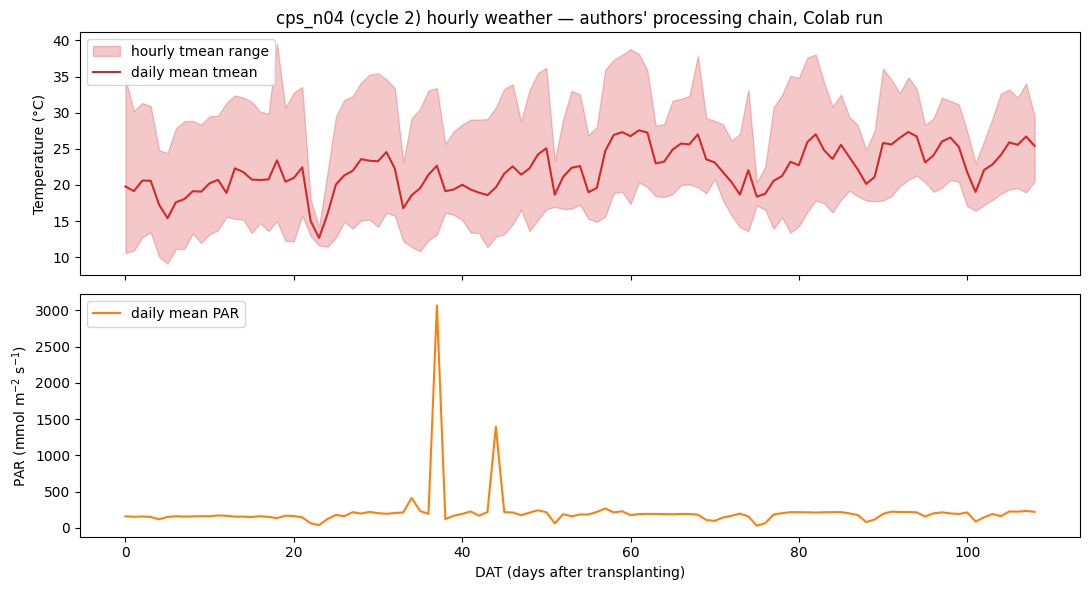

In [ ]:
import matplotlib.pyplot as plt
w = ds['weather']
daily = w.groupby('dat').agg(rad=('rad','mean'), tmean=('tmean','mean'),
                             tmin=('tmean','min'), tmax=('tmean','max')).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].fill_between(daily.dat, daily.tmin, daily.tmax, alpha=0.25, color='tab:red', label='hourly tmean range')
axes[0].plot(daily.dat, daily.tmean, color='tab:red', label='daily mean tmean')
axes[0].set_ylabel('Temperature (°C)'); axes[0].legend(loc='upper left')
axes[0].set_title('cps_n04 (cycle 2) hourly weather — authors\' processing chain, Colab run')
axes[1].plot(daily.dat, daily.rad, color='tab:orange', label='daily mean PAR')
axes[1].set_xlabel('DAT (days after transplanting)'); axes[1].set_ylabel('PAR (mmol m$^{-2}$ s$^{-1}$)')
axes[1].legend(loc='upper left')
fig.tight_layout(); fig.savefig('/content/preview_weather.png', dpi=90)
plt.show()

## 13. Input preview — monitored plant fresh mass (the assimilated stream)

The observation stream for the UKF: hourly mean plant fresh mass `w_fm_full` (kg) at node 2
(experiment `cps_n04`), with the hourly standard deviation. Values are relative to the
system's reference zero (`ref_zero`, 2019-07-13), so the first days can be slightly negative.

**日本語:** UKF で assimilation する観測系列(ノード 2 の植物生体重の 1 時間平均と標準偏差)を表示します。
基準ゼロ(2019-07-13)より前の数日間はわずかに負値になり得ます。

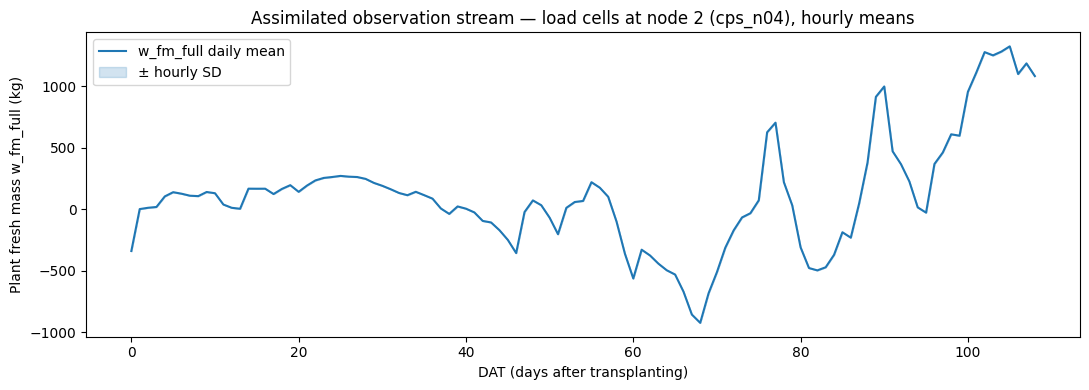

109 hourly observations at node 2


In [ ]:
obs_all = ds['obs']
node2 = obs_all[(obs_all.node == 2) & obs_all.w_fm_full.notna()]
daily_obs = node2.groupby('dat').agg(w=('w_fm_full','mean'), sd=('w_fm_full_sd','mean')).reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily_obs.dat, daily_obs.w, color='tab:blue', label='w_fm_full daily mean')
ax.fill_between(daily_obs.dat, daily_obs.w - daily_obs.sd, daily_obs.w + daily_obs.sd,
                alpha=0.2, color='tab:blue', label='± hourly SD')
ax.set_xlabel('DAT (days after transplanting)'); ax.set_ylabel('Plant fresh mass w_fm_full (kg)')
ax.set_title('Assimilated observation stream — load cells at node 2 (cps_n04), hourly means')
ax.legend(); fig.tight_layout(); fig.savefig('/content/preview_obs.png', dpi=90)
plt.show()
print(len(node2), 'hourly observations at node 2')

## 14. Open-loop Reduced State TOMGRO simulation

We call the authors' `run_simul` (from `simulations/run_Model_ReducedTomgro_oo.py`) with the
loaded parameters/states/weather — the same daily loop the authors use: each day integrates
hourly gross photosynthesis (Jones et al. formulation), maintenance respiration, node number,
LAI, fruit and mature-fruit dry mass. `gnvMod` parameters (calibrated by the authors for this
greenhouse) are used as published. This is the *open-loop* (no assimilation) reference.

**日本語:** 著者の `run_simul` をそのまま呼び出し、assimilation なしの open-loop シミュレーションを
実行します。パラメータは著者公開の gnvMod 較正値です。

In [ ]:
import time
rates = {'dn_dt': np.array(0.0, ndmin=1), 'dlai_dt': np.array(0.0, ndmin=1),
         'dw_dt': np.array(0.0, ndmin=1), 'dwf_dt': np.array(0.0, ndmin=1),
         'dwm_dt': np.array(0.0, ndmin=1)}
t0 = time.time()
state_tup = rt_run.run_simul(ds['info'].copy(), ds['params'].copy(),
                             dict(rates), ds['states'].copy(), ds['weather'].copy())
print(f'open-loop simulation finished in {time.time()-t0:.1f} s')
final = np.ravel(state_tup[0][-1])
print('final state (n, lai, w, wf, wm):', final.round(3))

open-loop simulation finished in 0.1 s
final state (n, lai, w, wf, wm): [ 45.986   0.65  204.722  70.128  50.059]


## 15. UKF assimilation of the plant fresh-mass stream

We run the authors' own `run_filter` (`assimilation/run_Filter.py`) with the configuration row
the authors marked for real-observation runs: `id=80` in `tables/runs_Filter.csv` —
**filt=ukf, model=tomgro, city=cps, calib=gnvMod, exp=4, sensor A, state_var=w,
meas_var=w_fm_full, P=1e-6, Q=20, case1** (copied verbatim from the table). The observation
model is the authors' `hx.W_ind_non_dest` — the cycle-2 linear mapping from the dry-mass state
`w` to expected plant fresh mass including roots (`w_full_fm ≈ 8.323·w + 0.474`, from
`measurementFunctions.py`), with observation error `R` taken from the measured hourly SD.

**日本語:** 著者の `run_filter` を、`runs_Filter.csv` の実データ用設定行(id=80)をそのまま用いて
実行します。観測モデルは著者の `W_ind_non_dest`(乾物状態 → 生体重へのサイクル別線形写像)、
観測誤差 R は計測された時間毎の SD から設定されます。

**Note:** `run_Filter.py` runs the authors' batch campaign at import time; this notebook executes
its source without that trailing block (see the adaptation notes).
**日本語(補足):** `run_Filter.py` は import 時にバッチ処理が動くため、末尾のバッチ部分を除いた
ソースから `run_filter` を取得します。

In [ ]:
# NOTE: assimilation/run_Filter.py ends with the authors' full batch campaign as
# MODULE-LEVEL code (a joblib Parallel sweep over all configs x 20 repetitions).
# Importing it would launch that hours-long campaign. We therefore execute the
# module source minus that trailing block, obtaining the authors' run_filter()
# and helpers verbatim (adaptation #3).
import types
_src_rf = open('assimilation/run_Filter.py').read()
_cut = _src_rf.index('# PAPER 2')
rf = types.ModuleType('assimilation.run_Filter')
rf.__file__ = 'assimilation/run_Filter.py'
exec(compile(_src_rf[:_cut], 'assimilation/run_Filter.py', 'exec'), rf.__dict__)
assert hasattr(rf, 'run_filter')
cfg = pd.read_csv('tables/runs_Filter.csv')
row = cfg[(cfg.run == 1) & (cfg.id == 80)].iloc[0].to_dict()
row['meas_var_j'] = row['meas_var']
row['meas_var'] = row['meas_var'].split(',')
row['rep'] = 1
row['param_pert'] = 'Qe'      # per state_var 'w', as in run_Filter.main_real
row['weather_pert'] = 'rad'   # as in run_Filter.main_real
row['states_names'] = ['n', 'lai', 'w', 'wf', 'wm']
row['seed'] = 43              # 42 + rep, as in main_real
row['model_err'] = None       # only used when Q is NaN; Q=20 here
print('UKF config:', {k: row[k] for k in ['filt','frequency','calib','exp','sensor_type','state_var','P','Q','R','N','case','id','config']})
ds2 = rt_run.load_dataset('cps', 'A', 'gnvMod', '4', 'monit')
t0 = time.time()
assim, all_states_upd, sigmas = rf.run_filter(ds2, row)
print(f'UKF finished in {time.time()-t0:.1f} s; {len(assim)} daily records')

UKF config: {'filt': 'ukf', 'frequency': 0.5, 'calib': 'gnvMod', 'exp': 4, 'sensor_type': 'A', 'state_var': 'w', 'P': 1e-06, 'Q': 20.0, 'R': nan, 'N': nan, 'case': 'case1', 'id': 80, 'config': 6}


UKF finished in 0.8 s; 109 daily records


## 16. Results — open-loop vs UKF vs observations

The filter updates the dry-mass state `w` daily. For comparison with the fresh-mass
observations we apply the authors' cycle-2 measurement model (`8.323·w + 0.474`) to both the
open-loop and UKF trajectories. The table below summarizes the daily states at the days with
observations; the CSV is saved next to the notebook for inspection.

**日本語:** open-loop と UKF の状態 `w` を、著者のサイクル 2 観測モデル(8.323·w + 0.474)で
生体重に換算して観測値と比較します。結果表は CSV にも保存されます。

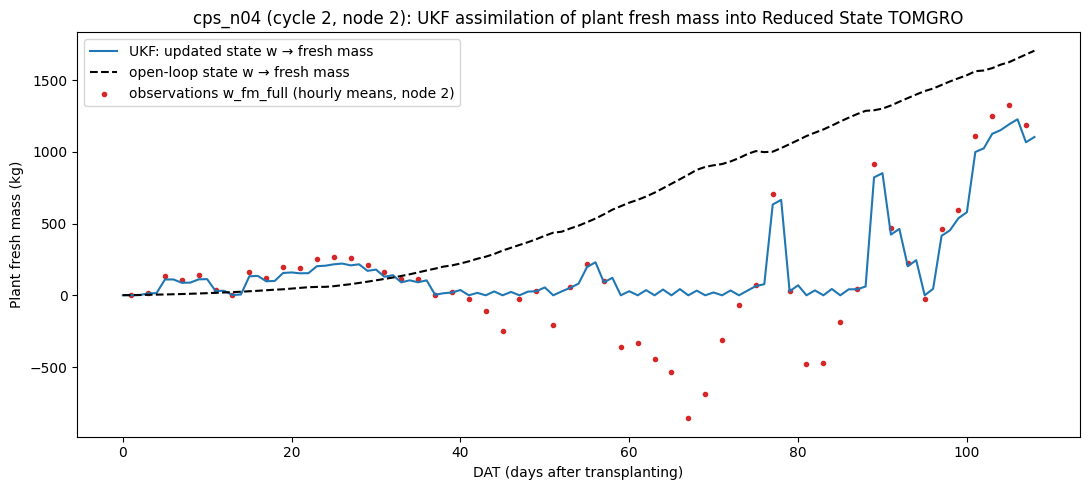

 dat  x_prior  x_post     obs                    gain  x_prior_fm  x_post_fm
   1    0.299   0.016   0.727 [[0.09520963206520436]]       2.964      0.604
   3    0.294   1.654  17.803  [[0.0961159681645677]]       2.922     14.243
   5    1.940  13.210 138.026 [[0.09611581021712677]]      16.617    110.421
   7   13.382  10.468 109.499 [[0.09611569779741687]]     111.857     87.599
   9   10.783  13.364 139.628 [[0.09611598775804994]]      90.225    111.703
  11   13.729   3.575  37.781 [[0.09611595426971044]]     114.743     30.225
  13    4.166   0.266   3.361 [[0.09611595629223159]]      35.150      2.689
  15    1.101  15.918 166.203 [[0.09611590728230296]]       9.635    132.962
  17   16.580  11.764 122.984 [[0.09611586572747394]]     138.474     98.387
  19   12.520  18.700 195.148 [[0.09611591731950855]]     104.682    156.119
  21   19.577  18.403 192.061 [[0.09611580641167239]]     163.422    153.649
  23   18.498  24.362 254.060 [[0.09611544344893283]]     154.439    203.248

In [ ]:
A = pd.DataFrame(assim, columns=['x_prior','P_prior','x_post','P_post','m_prior','mP_prior',
                                 'm_post','mP_post','obs','R','gain','resid','S','dat'])
S = pd.DataFrame(all_states_upd, columns=['n','lai','w','wf','wm','dat'])
# run_filter integrates every DAT present in the weather file (incl. DAT 0):
# state row 0 is the initial state, state row k is the state after A.dat[k-1].
ukf_dat = np.concatenate([[0], A.dat.values])
assert len(S) == len(A) + 1
W2F = lambda w: 8.3232752230702 * np.ravel(w) + 0.47353059300635  # authors' cycle-2 W_ind_dest
obs_pts = A[A.obs.notna()]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ukf_dat, W2F(S.w), color='tab:blue', label='UKF: updated state w → fresh mass')
# open-loop run_simul skips DAT 0: row i (i>=1) is the state after DAT i.
open_dats = [0] + sorted(int(d) for d in ds['weather'].dat.unique() if d > 0)
open_dat = np.array(open_dats[:len(state_tup[0])])
ax.plot(open_dat, W2F(state_tup[0][:, 2]), 'k--', label='open-loop state w → fresh mass')
ax.scatter(obs_pts.dat, obs_pts.obs, s=9, c='tab:red', label='observations w_fm_full (hourly means, node 2)')
ax.set_xlabel('DAT (days after transplanting)'); ax.set_ylabel('Plant fresh mass (kg)')
ax.set_title('cps_n04 (cycle 2, node 2): UKF assimilation of plant fresh mass into Reduced State TOMGRO')
ax.legend(); fig.tight_layout(); fig.savefig('/content/ukf_vs_openloop.png', dpi=90)
plt.show()
tab = obs_pts[['dat','x_prior','x_post','obs','gain']].copy()
tab['x_prior_fm'] = W2F(tab.x_prior); tab['x_post_fm'] = W2F(tab.x_post)
tab = tab.round(3)
print(tab.head(12).to_string(index=False))
out_csv = '/content/ukf_cps_n04_daily_states.csv'
S.round(4).to_csv(out_csv, index=False)
print('daily states saved to', out_csv)

## 17. Interpretation, validation record and references

**What was executed (this run):** the authors' full data-preparation R chain on the public
ReDu raw data, their Reduced State TOMGRO implementation for experiment `cps_n04` (cycle 2,
Campinas), and their FilterPy-based UKF assimilation of the load-cell plant fresh-mass stream
(config `id=80` from their own `runs_Filter.csv`), all on a fresh Colab CPU runtime. No prior
notebook outputs were reused; every number above comes from this run.

**What this demonstrates:** the paper's core mechanism — that continuous, high-frequency plant
monitoring data can be fed back into a process-based crop model through a Kalman filter to
correct growth estimates — runs end-to-end with the authors' own code and data. As in the
paper, the assimilated trajectory tracks the monitored mass and departs from the open-loop
simulation where the calibrated model drifts.

**Known limitations of this minimal demo (documented adaptations):**
1. Harvested-fruit mass is not added back to the scales (empty `harvests.csv`); in the real
   data, harvest events remove fruit mass from the measurement.
2. Only the monitoring mass stream is assimilated; image/LAI-based observations were out of
   reach (multi-GB archives) and destructive analyses are not in the public archive.
3. One cycle / one experiment — this is a partial demonstration, not a reproduction of the
   paper's dataset-level comparisons.
4. `assimilation/run_Filter.py` executes the authors' full batch campaign (joblib Parallel
   sweep) at module level on import; we execute the module source minus that trailing block
   to obtain `run_filter()` verbatim without launching the campaign.
5. The authors' monitoring observations are the 04:00 daily measurement per plant
   (`04a-joinDatasetMonitoring.R`); the reduced observation table keeps exactly that.
   The observation SD is recomputed from the authors' per-reading values (their
   `calcMeanSD` summarise shadows `w_fm_full` with the newly created mean column, so
   the shipped `w_fm_full_sd` is always NA), followed by the authors' own
   `05-joinDatasets.R` overrides (0.1 at DAT 0/1, forward-fill).
6. The authors' `run_simul` relies on legacy NumPy silently building a ragged object array
   from state attributes of different shapes; on NumPy ≥ 1.24 this raises, so the stacked
   values are raveled explicitly (numerically identical for this scalar state).
7. Two one-token bug fixes in the authors' R utilities and encoding normalization of their
   Latin-1 files were required to run their chain outside their Windows environment (all
   documented above).

**日本語:** 本ノートブックは、著者のコードと公開データを用いて、連続モニタリングデータを
UKF でプロセスベース作物モデルへ取り込むという論文の核となる仕組みを 1 サイクルで再現した
部分的なデモンストレーションです。収穫果実の質量の復元、画像・LAI 観測、EnKF 実験、
再較正は対象外であり、著者の R ユーティリティに 2 箇所の最小修正(文書化済み)を適用しました。

**References**
- Paper: DOI [10.1590/scielopreprints.7663](https://doi.org/10.1590/scielopreprints.7663); journal version 10.1016/j.inpa.2025.02.003.
- Code: [mnqoliveira/data-assimilation-tomato-models](https://github.com/mnqoliveira/data-assimilation-tomato-models), tag v0.3.0, commit `c7f9d90aad822a40ba1d09feb512a139747e03c7`, MIT License. Zenodo DOI of code record series: 10.5281/zenodo.7632419 (v0.2.0 archive: 10.5281/zenodo.8419405).
- Data: ReDu, doi:[10.25824/redu/EP4NGO](https://doi.org/10.25824/redu/EP4NGO), version 5 (2021-12-09).
- FilterPy: https://github.com/rlabbe/filterpy (v1.4.5). NASA POWER: power.larc.nasa.gov (daily, community=AG).